<a target="_blank" href="https://colab.research.google.com/github/visze/foundations_in_medicine/blob/master/biomedical_databases/tutorial.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# 🧬 Tutorial Biomedical Databases

## 🧬 Background

Several genes are linked to hereditary cancer, including **BRCA1**, **BRCA2**, and **TP53**. These genes play a crucial role in the body's ability to repair DNA damage and regulate cell growth. 🔬 Mutations in these genes can lead to an increased risk of developing certain types of cancer, particularly breast and ovarian cancer.

### ❓ Question


> **💡 Look up the gene TERT in various databases. What is its function, and what diseases are associated with mutations in this gene?**


TERT reactivation occurs frequently in human malignancies, especially advanced cancers. However, in vivo functions of TERT reactivation in cancer progression and the underlying mechanism are not fully understood.


TERT promoter mutations (TERT-p mutations) have been found in many types of cancer


TERT not only elongates telomeres and confers unlimited proliferative capacity on tumor cells, but is also involved in tumor progression and aggressiveness.

Besides coding mutations, regulatory mutations can also impact gene function. Gene coding regions constitute only around 2% of the human genome, while regulatory regions make up a much larger portion (up to 15-20% depending on the source). Their main purpose is to regulate the expression of genes. 🧫 Every cell has the same DNA sequence, but cells differ in purpose, shape, etc. We can define two different aspects of regulation:

1. **🗺️ Spatial regulation:**
   - Organs
   - Cell types
   - Single cells (e.g., different immune cells)
2. **⏱️ Temporal regulation:**
   - Cell cycle phase
   - Differentiation phase
   - Developmental stage
   - Induced transcription (environmental stimuli)

The regulation of transcription is controlled by the binding of proteins or RNA to regulatory nucleic acid sequences. These sequences are often classified into **promoters** and **enhancers**.

**🚦 Promoters** are typically located directly upstream of the gene they regulate and serve as the binding site for RNA polymerase and other transcription factors necessary for initiating transcription.

**⚡ Enhancers**, on the other hand, can be located far away from the gene they regulate (upstream, downstream, or even within introns) and function to increase the transcriptional activity of a gene by providing additional binding sites for transcription factors.

![Regulation](https://github.com/visze/foundations_in_medicine/blob/master/biomedical_databases/resources/picture/regulation.png?raw=1)

Mutations in regulatory regions can affect gene expression levels, leading to diseases such as cancer. 🦠 TERT promoter mutations have been identified in various cancers, including melanoma, glioblastoma, and bladder cancer. These mutations can lead to increased TERT expression, which may contribute to the uncontrolled growth of cancer cells. 📈

## 🔍 Variants in the TERT promoter region

Now we will look up different databases to find information about variants in the TERT promoter region. 📚 We'll try to solve this question "programmatically"—this means using code to query the databases instead of using their web interfaces (when it makes sense). 💻

### ❓ Question

> **💡 Find out the genomic coordinates (GRCh38) of the TERT promoter region.**

📌 Helpful resources:
- [UCSC Genome Browser](https://genome.ucsc.edu/) 🌐
- [ENCODE SCREEN database](https://screen.wenglab.org). SCREEN is a database derived from ENCODE data. It annotates candidate cis-regulatory elements (cCREs) in the human and mouse genomes based on a large number of functional genomics experiments. 🧪

### 🌍 Population variants from gnomAD

The overall question we want to solve is: are there variants in the TERT promoter region in the human population that can lead to misregulation of TERT? To answer this question, we will use the [gnomAD database](https://gnomad.broadinstitute.org/). 🧬 gnomAD (Genome Aggregation Database) is a comprehensive resource that aggregates and harmonizes exome and genome sequencing data from a wide variety of large-scale sequencing projects. It provides allele frequency data for genetic variants across diverse populations, making it a valuable tool for researchers studying human genetics and disease. 🧫

gnomAD uses [GraphQL](https://graphql.org/) to provide programmatic access to their database. 🔌 GraphQL is an alternative to REST APIs. Instead of multiple endpoints, there is only one endpoint. The user defines the structure of the response data in the request. ✨

First, we need to install the GQL GraphQL client library for Python. 📦

In [1]:
%%bash
pip install gql aiohttp pandas

Starting with GraphQL is not that easy. 🤔 But many databases use it, and so it might be helpful to try it out and understand the concept. gnomAD has a very short documentation page here: https://gnomad.broadinstitute.org/data#api.

However, it only shows you the `gene` query. But there is more! 🎯 You have `region`, `transcript`, `variant`, and many more searches. You can find them by clicking on this link: https://gnomad.broadinstitute.org/api? and click through the panel on the right side on `QQuery` and further.

Also, it is important to understand what the query returns because you have to specifically add this to your query. E.g. the `region` query returns a `Region` object. You can find out what fields are available for this object by clicking on the `Region` link in the panel on the right side. 📋

### ❓ TODO

> **💡 Insert your region in the query by setting the variables `chrom`, `start`, and `stop`**

In [6]:
from gql import gql, Client
from gql.transport.aiohttp import AIOHTTPTransport

transport = AIOHTTPTransport(url="https://gnomad.broadinstitute.org/api")
client = Client(transport=transport, fetch_schema_from_transport=True)

# TODO DEFINE YOUR TERT PROMOTER REGION HERE
# Define region variables
chrom = "1" # like "1"
start = 1294944
 # like 1000000
stop = 1295294 # like 1010000

query = gql(
  f"""
  query RegionQuery {{
    region(chrom: "{chrom}", start: {start}, stop: {stop}, reference_genome: GRCh38) {{
    variants(dataset: gnomad_r4) {{
      variant_id
      chrom
      pos
      ref
      alt
      joint {{
      ac
      an
      }}
    }}
    }}
  }}
  """
)
result = await client.execute_async(query)
print(result)

{'region': {'variants': [{'variant_id': '1-1294944-A-C', 'chrom': '1', 'pos': 1294944, 'ref': 'A', 'alt': 'C', 'joint': {'ac': 0, 'an': 869072}}, {'variant_id': '1-1294944-A-G', 'chrom': '1', 'pos': 1294944, 'ref': 'A', 'alt': 'G', 'joint': {'ac': 1, 'an': 869074}}, {'variant_id': '1-1294945-G-T', 'chrom': '1', 'pos': 1294945, 'ref': 'G', 'alt': 'T', 'joint': {'ac': 0, 'an': 849668}}, {'variant_id': '1-1294945-G-C', 'chrom': '1', 'pos': 1294945, 'ref': 'G', 'alt': 'C', 'joint': {'ac': 25, 'an': 849550}}, {'variant_id': '1-1294946-G-T', 'chrom': '1', 'pos': 1294946, 'ref': 'G', 'alt': 'T', 'joint': {'ac': 0, 'an': 849838}}, {'variant_id': '1-1294946-G-A', 'chrom': '1', 'pos': 1294946, 'ref': 'G', 'alt': 'A', 'joint': {'ac': 0, 'an': 849838}}, {'variant_id': '1-1294947-G-GC', 'chrom': '1', 'pos': 1294947, 'ref': 'G', 'alt': 'GC', 'joint': {'ac': 4, 'an': 799926}}, {'variant_id': '1-1294947-G-C', 'chrom': '1', 'pos': 1294947, 'ref': 'G', 'alt': 'C', 'joint': {'ac': 1, 'an': 799926}}, {'va

You see we get a JSON string back with our results. It is very easy to create a pandas DataFrame out of it. 🐼 We only have to take care of nested objects (which is only the `joint` field).

In [10]:
import pandas as pd

# Extract variant data from the result dictionary
variants_data = result['region']['variants']

# Create a pandas DataFrame
df_gnomad_variants = pd.DataFrame(variants_data)

# Expand the 'joint' column into separate 'ac' and 'an' columns
df_gnomad_variants['ac'] = df_gnomad_variants['joint'].apply(lambda x: x['ac'])
df_gnomad_variants['an'] = df_gnomad_variants['joint'].apply(lambda x: x['an'])

# Drop the original 'joint' column
df_gnomad_variants = df_gnomad_variants.drop(columns=['joint'])

# Display the DataFrame
df_gnomad_variants

,variant_id,chrom,pos,ref,alt,ac,an
0,1-1294944-A-C,1,1294944,A,C,0,869072
1,1-1294944-A-G,1,1294944,A,G,1,869074
2,1-1294945-G-T,1,1294945,G,T,0,849668
3,1-1294945-G-C,1,1294945,G,C,25,849550
4,1-1294946-G-T,1,1294946,G,T,0,849838
...,...,...,...,...,...,...,...
498,1-1295285-CCT-C,1,1295285,CCT,C,50,152274
499,1-1295288-G-C,1,1295288,G,C,1,151988
500,1-1295289-ACAGT-A,1,1295289,ACAGT,A,7,152018
501,1-1295290-C-T,1,1295290,C,T,2,152162


### ❓ Question

> **💡 How many variants did you find?**
>
> **💡 What is the most common variant?**

In [14]:
# Calculate total number of variants found
total_variants = len(df_gnomad_variants)
print(f"Total variants found in the TERT promoter region: {total_variants}")

# Find the most common variant (the one with the highest allele count 'ac')
# Filter out cases if allele count could be missing, and sort to find the highest
if not df_gnomad_variants.empty:
    most_common = df_gnomad_variants.loc[df_gnomad_variants['ac'].idxmax()]
    print(f"\nMost common variant:")
    print(f"  ID: {most_common['variant_id']}")
    print(f"  Position: {most_common['pos']}")
    print(f"  Ref/Alt: {most_common['ref']} -> {most_common['alt']}")
    print(f"  Allele Count (AC): {most_common['ac']}")
    print(f"  Allele Number (AN): {most_common['an']}")
    print(f"  Allele Frequency (AF): {most_common['ac'] / most_common['an'] if most_common['an'] > 0 else 0:.6f}")
else:
    print("No variants found in the DataFrame.")

Total variants found in the TERT promoter region: 503

Most common variant:
  ID: 1-1295039-T-C
  Position: 1295039
  Ref/Alt: T -> C
  Allele Count (AC): 125456
  Allele Number (AN): 572550
  Allele Frequency (AF): 0.219118


=== Variant Type Distribution ===


,Count
variant_type,
SNV,462
Deletion,28
Insertion,13


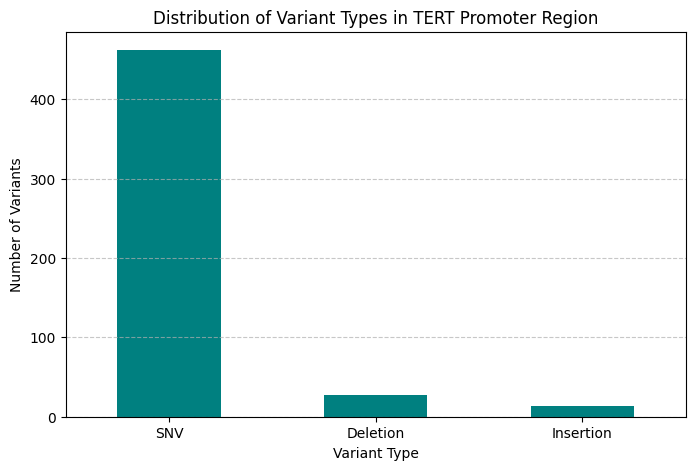

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Classify variant types
def classify_variant(row):
    ref_len = len(str(row['ref']))
    alt_len = len(str(row['alt']))
    if ref_len == 1 and alt_len == 1:
        return 'SNV' # Single Nucleotide Variant
    elif ref_len < alt_len:
        return 'Insertion'
    elif ref_len > alt_len:
        return 'Deletion'
    else:
        return 'Complex Substitution'

df_gnomad_variants['variant_type'] = df_gnomad_variants.apply(classify_variant, axis=1)

# Count and display distribution of variant types
type_counts = df_gnomad_variants['variant_type'].value_counts()
print("=== Variant Type Distribution ===")
display(type_counts.to_frame(name='Count'))

# Visualize
plt.figure(figsize=(8, 5))
type_counts.plot(kind='bar', color='teal')
plt.title('Distribution of Variant Types in TERT Promoter Region')
plt.ylabel('Number of Variants')
plt.xlabel('Variant Type')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 🏥 Clinically annotated variants from ClinVar

Now we want to find out which variants have already been annotated with any clinical significance (no matter if related to cancer or not). For this, we will use the [ClinVar database](https://www.ncbi.nlm.nih.gov/clinvar/). 🏥 ClinVar is a publicly accessible database that aggregates information about genomic variations and their relationship to human health. It is maintained by the National Center for Biotechnology Information (NCBI), a part of the U.S. National Library of Medicine. 📚

ClinVar usually provides downloadable files for bulk access to their data. 📥 Usually, people use these files. ClinVar has an API for submission of new data and also for retrieval. However, ClinVar data is also available through the gnomAD API (maybe not the most recent one). But we already used gnomAD successfully, so we'll continue here with gnomAD to avoid learning any new API. 🎓

ClinVar data is available through the `clinvar_variants` field in the gnomAD API. You can query by variant ID or search within a region. 🔎

In [18]:
# Query ClinVar variants within a region
clinvar_region_query = gql(
    f"""
    query ClinVarRegionQuery {{
      region(chrom: "{chrom}", start: {start}, stop: {stop}, reference_genome: GRCh38) {{
        clinvar_variants {{
          variant_id
          chrom
          pos
          ref
          alt
          clinical_significance
        }}
      }}
    }}
    """
)

clinvar_region_result = await client.execute_async(clinvar_region_query)
print("\nClinVar Region Query Result:")
print(clinvar_region_result)


ClinVar Region Query Result:
{'region': {'clinvar_variants': [{'variant_id': '5-1295020-C-G', 'chrom': '5', 'pos': 1295020, 'ref': 'C', 'alt': 'G', 'clinical_significance': 'Uncertain significance'}, {'variant_id': '5-1295034-C-A', 'chrom': '5', 'pos': 1295034, 'ref': 'C', 'alt': 'A', 'clinical_significance': 'Uncertain significance'}, {'variant_id': '5-1295042-T-C', 'chrom': '5', 'pos': 1295042, 'ref': 'T', 'alt': 'C', 'clinical_significance': 'Uncertain significance'}, {'variant_id': '5-1295045-CT-C', 'chrom': '5', 'pos': 1295045, 'ref': 'CT', 'alt': 'C', 'clinical_significance': 'Uncertain significance'}, {'variant_id': '5-1295046-T-G', 'chrom': '5', 'pos': 1295046, 'ref': 'T', 'alt': 'G', 'clinical_significance': 'Conflicting classifications of pathogenicity'}, {'variant_id': '5-1295046-T-A', 'chrom': '5', 'pos': 1295046, 'ref': 'T', 'alt': 'A', 'clinical_significance': 'Uncertain significance'}, {'variant_id': '5-1295046-T-C', 'chrom': '5', 'pos': 1295046, 'ref': 'T', 'alt': 'C',

Let's create a pandas DataFrame out of it again. 🐼

In [19]:

# Extract variant data from the result dictionary
clinvar_variants_data = clinvar_region_result['region']['clinvar_variants']

# Create a pandas DataFrame
df_clinvar_variants = pd.DataFrame(clinvar_variants_data)

# Display the DataFrame
df_clinvar_variants

,variant_id,chrom,pos,ref,alt,clinical_significance
0,5-1295020-C-G,5,1295020,C,G,Uncertain significance
1,5-1295034-C-A,5,1295034,C,A,Uncertain significance
2,5-1295042-T-C,5,1295042,T,C,Uncertain significance
3,5-1295045-CT-C,5,1295045,CT,C,Uncertain significance
4,5-1295046-T-G,5,1295046,T,G,Conflicting classifications of pathogenicity
5,5-1295046-T-A,5,1295046,T,A,Uncertain significance
6,5-1295046-T-C,5,1295046,T,C,Uncertain significance
7,5-1295059-G-C,5,1295059,G,C,Uncertain significance
8,5-1295060-C-G,5,1295060,C,G,Uncertain significance
9,5-1295071-CG-C,5,1295071,CG,C,Uncertain significance


### ❓ Question

> **💡 How many ClinVar variants did you find?**
>
> **💡 Are all of them pathogenic? What is their clinical significance?**

In [20]:
# TODO ADD YOUR CODE HERE

Total ClinVar variants found: 21

Clinical significance distribution:
clinical_significance
Uncertain significance                          17
Conflicting classifications of pathogenicity     2
Pathogenic                                       1
Likely benign                                    1
Name: count, dtype: int64


### 🔗 Annotate population variants with ClinVar data

Merge gnomAD variants with ClinVar variants to find the clinical significance of variants in the region. 🧩

In [21]:
# Merge gnomAD variants with ClinVar variants
# Create a common key for merging based on variant_id, chromosome, position, ref, and alt
df_merged_variants = df_gnomad_variants.merge(
    df_clinvar_variants,
    left_on=['variant_id', 'chrom', 'pos', 'ref', 'alt'],
    right_on=['variant_id', 'chrom', 'pos', 'ref', 'alt'],
    how='left'
)

# Display the merged DataFrame
df_merged_variants

,variant_id,chrom,pos,ref,alt,ac,an,variant_type,clinical_significance
0,1-1294944-A-C,1,1294944,A,C,0,869072,SNV,NaN
1,1-1294944-A-G,1,1294944,A,G,1,869074,SNV,NaN
2,1-1294945-G-T,1,1294945,G,T,0,849668,SNV,NaN
3,1-1294945-G-C,1,1294945,G,C,25,849550,SNV,NaN
4,1-1294946-G-T,1,1294946,G,T,0,849838,SNV,NaN
...,...,...,...,...,...,...,...,...,...
498,1-1295285-CCT-C,1,1295285,CCT,C,50,152274,Deletion,NaN
499,1-1295288-G-C,1,1295288,G,C,1,151988,SNV,NaN
500,1-1295289-ACAGT-A,1,1295289,ACAGT,A,7,152018,Deletion,NaN
501,1-1295290-C-T,1,1295290,C,T,2,152162,SNV,NaN


### ❓ Question

> **💡 What clinical significance do the top 5 variants with the highest allele frequency have?**
>
> **💡 What is the allele frequency or allele count of pathogenic variants?**

In [23]:
# TODO ADD YOUR CODE HERE

=== Top 5 Variants with the Highest Allele Frequency ===
Variant: 1-1295039-T-C | AF: 0.219118 | Significance: Not in ClinVar
Variant: 1-1295028-A-C | AF: 0.076336 | Significance: Not in ClinVar
Variant: 1-1295060-C-A | AF: 0.073877 | Significance: Not in ClinVar
Variant: 1-1295037-C-T | AF: 0.006741 | Significance: Not in ClinVar
Variant: 1-1295027-A-G | AF: 0.001235 | Significance: Not in ClinVar

=== Pathogenic Variants and their Allele Frequency / Counts ===


,variant_id,chrom,pos,ref,alt,clinical_significance
17,5-1295135-G-A,5,1295135,G,A,Pathogenic



Note: ClinVar pathogenic variants are listed above (on Chromosome 5), but do not appear in population germline data (Chromosome 1). This is common for critical cancer somatic/driver variants.


## 🎯 Linking Motifs to Variant Effects

We know that regulation is controlled by the binding of proteins or RNA to regulatory nucleic acid sequences. 🧬 The proteins are called **transcription factors (TFs)**. TFs bind to specific DNA sequences, often referred to as **motifs**. 🔑 Mutations in these motifs can disrupt the binding of TFs, but also create new binding sites, leading to changes in gene expression. The direction of the expression change depends on whether the binding TF is an activator or repressor of transcription. ⚖️

Here is a visualization of an example motif. You can see which bases are preferred at which position in the motif. The higher the letter, the more often this base is found at this position in known binding sites for this TF. Usually motifs are stored as position weight matrices (PWMs) or position frequency matrices (PFMs).

![example motif](https://hocomoco14.autosome.org/final_bundle/hocomoco14/H14CORE/logo_large/ALX1.H14CORE.0.SM.B_direct.png)

Keep in mind that binding of TFs is highly tissue-specific. 🎭 Not every TF is present in every cell type. Therefore, mutations in motifs may have different effects depending on the cellular context. Also, we will find many more motifs than actual binding events. Just because a motif is present does not mean that the TF actually binds there in a given cell type. ⚠️

We will now put our variants into the context of **transcription factor (TF) binding motifs**. 🧬 TFs bind to specific DNA sequences, so-called **motifs**. A single nucleotide change can either **destroy an existing binding site** or **create a new one**, which can change gene expression and contribute to disease. ⚖️

Computational tools can scan DNA sequences for known motifs using position weight matrices (PWMs). In this tutorial we will **not run a motif scan ourselves**. Instead, we will briefly look at how such a scan works and then focus on **functional evidence** from massively parallel reporter assays (MPRAs). 🧪

---

### 🔍 Motif Identification from Sequence

Let's explore how to identify transcription factor binding motifs in DNA sequences. 🧬✨

#### 🗄️ TFBS Databases: JASPAR & HOCOMOCO

Transcription factors (TFs) regulate gene expression by binding to specific DNA motifs. 🔗 Identifying these motifs is crucial for understanding gene regulation, cell differentiation, and disease. 🎯

**Key Databases:**
- [JASPAR](https://jaspar.elixir.no/) 📚
- [HOCOMOCO](https://hocomoco14.autosome.org/) 📊

Both provide position weight matrices (PWMs) for TFBSs.  
> **⚠️ Note:**  
> Genome-wide PWM scanning can yield many false positives due to short motif lengths and genome size.

A commonly used resource is **HOCOMOCO v14 (H14)**, which provides motifs in `.meme` format. 📄

- **🏆 HOCOMOCO v14:**  
  - 1,595 TF binding models for 1,107 human TFs (and 809 mouse orthologs) 🐭
  - Built from ChIP-seq, HT-SELEX, GHT-SELEX, SMiLE-seq, and PBM data 🧪
  - Includes manual curation and benchmarking ✅
  - [Download HOCOMOCO v14](https://hocomoco14.autosome.org/downloads_v14) 📥

<img src="https://github.com/visze/foundations_in_medicine/blob/master/biomedical_databases/resources/picture/hocomocov14_logo.png?raw=1" alt="HOCOMOCO v14" width="250"> 🖼️

#### 🛠️ TFBS Identification Tools

Several tools can scan sequences for PWM matches: 🔧

- **FIMO** (Find Individual Motif Occurrences, MEME suite) 🎯
- **HOMER** (Hypergeometric Optimization of Motif EnRichment) 📊
- ...and more! ✨

Tools like **FIMO** are commonly used to search for motif matches in DNA sequences. 🚀

**📋 FIMO Usage:**

- Input: TFBS database (.meme format) + FASTA sequences 📄
- Output: Table of motif matches (`motif_id`, sequence name, start/end, matched sequence, p-value, q-value, etc.) 📊

In the next section we will look at the idea behind this approach, without running FIMO ourselves. 🔬

#### 🔍 Motif Scanning with FIMO (Theory)

Tools such as [FIMO](https://meme-suite.org/meme/tools/fimo) (Find Individual Motif Occurrences) from the MEME suite scan DNA sequences for matches to known motifs. 🛠️

**Input:**
- A motif database in `.meme` format, e.g. [JASPAR](https://jaspar.elixir.no/) or [HOCOMOCO](https://hocomoco14.autosome.org/)
- One or more DNA sequences in FASTA format

**Output:**
- Motif ID and matched position
- Matched sequence and strand
- p-value and q-value for each match

> **⚠️ Keep in mind:** Motifs are short, so a genome-wide scan produces many chance matches. A predicted motif does not automatically mean that the TF binds there. Binding also depends on TF expression, chromatin accessibility, and the cellular context. 🧫

### 🧪 Functional Evidence: Massively Parallel Reporter Assays (MPRAs)

Computational motif predictions are only a hypothesis. To measure the effect of a variant on regulatory activity, we can use reporter assays. 🧪

- **Luciferase reporter assay:** one regulatory sequence is cloned upstream of a luciferase gene; the light signal reports its activity. It is accurate but low-throughput. 💡
- **Massively Parallel Reporter Assay (MPRA):** thousands of regulatory sequences are tested in parallel, each linked to a unique barcode and a reporter gene. This allows us to measure the effect of many variants in a single experiment. 📊

![Luciferase assay versus MPRA](https://github.com/visze/foundations_in_medicine/blob/master/biomedical_databases/resources/picture/luciferase_vs_mpra.png?raw=1)

> **💡 Note:** A detailed explanation of MPRAs will follow later in the Machine Learning Perspectives module. Here we only use them as functional evidence for the effects of variants on regulatory activity. 🚀

### 🔬 Saturation Mutagenesis of the TERT Promoter

Saturation mutagenesis combines MPRA with systematic variant scanning: every position in a regulatory region is mutated and the effect on expression is measured. 🧬

Go to https://kircherlab.bihealth.org/satMutMPRA/ → **Promoter: TERT** → **Variant plot** and locate the variants from our analysis. 👀


### ❓ Question

> **💡 Which positions show the strongest effects on TERT expression?**
>
> **💡 Do the variants you found earlier fall into these positions?**
>
> **💡 Can you explain why some variants increase and others decrease expression?**

### 🧬 Well-Known TERT Promoter Driver Mutations

The TERT promoter is one of the most frequently mutated regulatory regions in cancer. Recurrent driver mutations are found in **glioma**, **bladder cancer**, and **melanoma**. 🦠 Many of these mutations create new binding sites for ETS transcription factors such as GABPA, which can increase TERT expression. 📈

In this tutorial we will look at five well-known variants (GRCh38, chromosome 5):

| Variant | Position |
|---|---|
| `5-1295112-G-A` | chr5:1295112 |
| `5-1295135-G-A` | chr5:1295135 |
| `5-1295046-T-G` | chr5:1295046 |
| `5-1295043-G-T` | chr5:1295043 |
| `5-1295034-C-A` | chr5:1295034 |

**Task:** Look up these variants in the population databases we used earlier (gnomAD and ClinVar). Are they present in the general population? What is their clinical significance? Why might cancer driver mutations be absent or very rare in gnomAD? 🤔

In [24]:
# Look up the well-known TERT promoter driver mutations in gnomAD
driver_variant_ids = [
    "5-1295112-G-A",
    "5-1295135-G-A",
    "5-1295046-T-G",
    "5-1295043-G-T",
    "5-1295034-C-A",
]

driver_region_chrom = "5"
driver_region_start = 1295020
driver_region_stop = 1295160

driver_gnomad_query = gql(
    f"""
    query DriverVariantsQuery {{
      region(chrom: "{driver_region_chrom}", start: {driver_region_start}, stop: {driver_region_stop}, reference_genome: GRCh38) {{
        variants(dataset: gnomad_r4) {{
          variant_id
          chrom
          pos
          ref
          alt
          joint {{
            ac
            an
          }}
        }}
      }}
    }}
    """
)

driver_gnomad_result = await client.execute_async(driver_gnomad_query)
df_driver_gnomad = pd.DataFrame(driver_gnomad_result["region"]["variants"])

if not df_driver_gnomad.empty:
    df_driver_gnomad["ac"] = df_driver_gnomad["joint"].apply(lambda x: x["ac"] if x else None)
    df_driver_gnomad["an"] = df_driver_gnomad["joint"].apply(lambda x: x["an"] if x else None)
    df_driver_gnomad = df_driver_gnomad.drop(columns=["joint"])

df_driver_gnomad[df_driver_gnomad["variant_id"].isin(driver_variant_ids)] if "variant_id" in df_driver_gnomad else df_driver_gnomad

,variant_id,chrom,pos,ref,alt,ac,an
41,5-1295034-C-A,5,1295034,C,A,6,1224982
67,5-1295043-G-T,5,1295043,G,T,0,1193064
72,5-1295046-T-G,5,1295046,T,G,43,1165730
351,5-1295135-G-A,5,1295135,G,A,13,484372


In [25]:
# Look up the same variants in ClinVar
driver_clinvar_query = gql(
    f"""
    query DriverClinVarQuery {{
      region(chrom: "{driver_region_chrom}", start: {driver_region_start}, stop: {driver_region_stop}, reference_genome: GRCh38) {{
        clinvar_variants {{
          variant_id
          chrom
          pos
          ref
          alt
          clinical_significance
        }}
      }}
    }}
    """
)

driver_clinvar_result = await client.execute_async(driver_clinvar_query)
df_driver_clinvar = pd.DataFrame(driver_clinvar_result["region"]["clinvar_variants"])

df_driver_clinvar[df_driver_clinvar["variant_id"].isin(driver_variant_ids)] if "variant_id" in df_driver_clinvar else df_driver_clinvar

,variant_id,chrom,pos,ref,alt,clinical_significance
1,5-1295034-C-A,5,1295034,C,A,Uncertain significance
4,5-1295046-T-G,5,1295046,T,G,Conflicting classifications of pathogenicity
17,5-1295135-G-A,5,1295135,G,A,Pathogenic



### ❓ Question: What do you observe?

> **💡 Are the driver variants present in gnomAD? If yes, what does this mean?**
>
> **💡 What does ClinVar say about their clinical significance?**
>
> **💡 Why is a variant that is common in tumors not necessarily common in the germline?**

Discuss your observations with your neighbor and compare them with the slides shown in class. 🗣️